# 02 - Cleaning and EDA: NYC Citi Bike

**Who worked on this:Mohammeed abu Qamar and willem starekx
**Input:** `citibike_data/parquet/*.parquet` (made in `01_download.ipynb`, 10% sample per month of 2025)
**Output:** `citibike_data/citibike_clean.parquet`

**Plan**
1. First look at the data
2. Column names, duplicates, NA values
3. Outliers (duration, coordinates, speed), each time with a before/after check
4. Categoricals and feature engineering
5. Aggregations and visualisations
6. Testable hypotheses with statistical evidence
7. Save the cleaned data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy import stats

sns.set_theme(style="whitegrid")
PQ_DIR = Path("citibike_data/parquet")
df = pd.read_parquet(PQ_DIR)
n_raw = len(df)
print(df.shape)

(4577110, 13)


## 1. First look
Shape, dtypes, memory and a few rows, so we know what we are dealing with.

In [2]:
display(df.head())
display(df.dtypes)
print(f"Memory: {df.memory_usage(deep=True).sum() / 1e6:.0f} MB")

,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual
0,704BA255678C0795,electric_bike,2025-01-17 04:09:24.388,2025-01-17 04:13:28.903,Milton St & Franklin St,5752.07,N Henry St & Norman Ave,5656.03,40.729060,-73.957790,40.727700,-73.943950,member
1,E50764104918C8D2,electric_bike,2025-01-02 06:35:24.675,2025-01-02 06:41:25.314,1 Ave & E 18 St,5854.09,Greenwich Ave & 8 Ave,6072.06,40.733812,-73.980544,40.739017,-74.002638,member
2,5DD850063DB9DBB3,electric_bike,2025-01-11 15:48:32.363,2025-01-11 15:52:50.538,Metropolitan Ave & Bedford Ave,5308.04,Hope St & Union Ave,5187.03,40.715348,-73.960241,40.711674,-73.951413,member
3,A3B59CE2BE45CCD5,electric_bike,2025-01-08 14:38:23.337,2025-01-08 14:46:20.487,W 52 St & 5 Ave,6700.01,W 41 St & 8 Ave,6602.03,40.759923,-73.976485,40.756405,-73.990026,member
4,11821BB833B1289A,electric_bike,2025-01-10 11:59:39.618,2025-01-10 12:04:57.654,Broadway & E 14 St,5905.12,Lafayette St & Grand St,5422.09,40.734546,-73.990741,40.720280,-73.998790,member


ride_id                          str
rideable_type                    str
started_at            datetime64[us]
ended_at              datetime64[us]
start_station_name               str
start_station_id                 str
end_station_name                 str
end_station_id                   str
start_lat                    float64
start_lng                    float64
end_lat                      float64
end_lng                      float64
member_casual                    str
dtype: object

Memory: 884 MB


## 2. Column names, duplicates and NA values
### 2a. Column names
Names are already `snake_case`, but we normalise them anyway (strip, lowercase) so the final pipeline does not break if a month has a slightly different header. We also shorten `lng` to `lon` is *not* done: we keep the original names to stay consistent with the source data.

In [3]:
df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_")
print(list(df.columns))

['ride_id', 'rideable_type', 'started_at', 'ended_at', 'start_station_name', 'start_station_id', 'end_station_name', 'end_station_id', 'start_lat', 'start_lng', 'end_lat', 'end_lng', 'member_casual']


### 2b. Duplicates
`ride_id` should be unique. We check this and drop duplicates, then verify that none are left.

In [4]:
dups = df.duplicated(subset="ride_id").sum()
print("Duplicate ride_ids before:", dups)
df = df.drop_duplicates(subset="ride_id")
print("Duplicate ride_ids after: ", df.duplicated(subset="ride_id").sum())

Duplicate ride_ids before: 0
Duplicate ride_ids after:  0


### 2c. Missing values
First *where* are the NAs, and are they random? Citi Bike also has dockless e-bikes that can end a trip outside a station, so missing end stations may be structural rather than errors.

In [5]:
na = df.isna().mean().mul(100).round(2).sort_values(ascending=False)
display(na[na > 0].to_frame("% missing"))

# Are the missing stations related to bike type?
display(df.assign(end_station_missing=df["end_station_name"].isna())
          .groupby("rideable_type")["end_station_missing"].mean().mul(100).round(2)
          .to_frame("% trips without end station"))

,% missing
end_station_id,0.28
end_lat,0.28
end_lng,0.28
end_station_name,0.27
start_station_name,0.04
start_lat,0.04
start_station_id,0.04
start_lng,0.04


,% trips without end station
rideable_type,
classic_bike,0.07
electric_bike,0.35


**Decision (fill in after you looked at the output above):**
- Missing station names/ids: kept. They are legitimate (bike locked outside a station), so we fill them with `"no_station"` instead of dropping or imputing.
- Missing `end_lat`/`end_lng`: we cannot compute distance, and the share is tiny, so we drop those rows.

*Check:* afterwards there must be no NAs left in the columns we need.

In [6]:
station_cols = ["start_station_name","start_station_id","end_station_name","end_station_id"]
df[station_cols] = df[station_cols].fillna("no_station")

before = len(df)
df = df.dropna(subset=["end_lat","end_lng","start_lat","start_lng","started_at","ended_at"])
print(f"Dropped {before-len(df):,} rows without coordinates/timestamps ({(before-len(df))/before:.3%})")
print("Remaining NAs:", int(df.isna().sum().sum()))

Dropped 14,668 rows without coordinates/timestamps (0.320%)
Remaining NAs: 0


## 3. Outliers
### 3a. Trip duration
We create `duration_min` and look at it *before* filtering. Negative or zero durations are impossible. Very short rides (< 1 min) are mostly false starts or docking problems, and extremely long rides (> 24 h) are almost certainly lost, stolen or unreturned bikes.

In [7]:
df["duration_min"] = (df["ended_at"] - df["started_at"]).dt.total_seconds() / 60
before_desc = df["duration_min"].describe(percentiles=[.01,.5,.99,.999]).round(1)
display(before_desc.to_frame("before cleaning"))

print("duration <= 0 :", (df.duration_min <= 0).sum())
print("duration < 1  :", (df.duration_min < 1).sum())
print("duration > 24h:", (df.duration_min > 24*60).sum())

,before cleaning
count,4562442.0
mean,12.3
std,18.1
min,-57.7
1%,1.4
50%,8.8
99%,55.5
99.9%,143.1
max,1500.0


duration <= 0 : 59
duration < 1  : 59
duration > 24h: 35


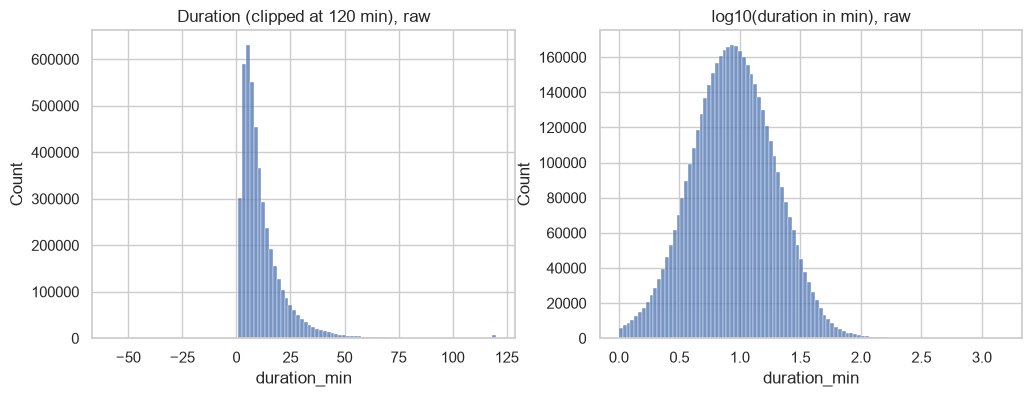

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["duration_min"].clip(upper=120), bins=100, ax=ax[0])
ax[0].set_title("Duration (clipped at 120 min), raw")
sns.histplot(np.log10(df.loc[df.duration_min > 0, "duration_min"]), bins=100, ax=ax[1])
ax[1].set_title("log10(duration in min), raw")
plt.show()

Rule: keep trips between 1 minute and 24 hours. The cut-offs are domain-based, not just statistical, which is easier to defend.

In [9]:
before = len(df)
df = df[(df.duration_min >= 1) & (df.duration_min <= 24*60)]
print(f"Removed {before-len(df):,} rows ({(before-len(df))/before:.2%})")
display(df["duration_min"].describe(percentiles=[.01,.5,.99,.999]).round(1).to_frame("after cleaning"))

Removed 94 rows (0.00%)


,after cleaning
count,4562348.0
mean,12.3
std,17.6
min,1.0
1%,1.4
50%,8.8
99%,55.5
99.9%,142.6
max,1435.1


### 3b. Coordinates
Some rows have `0,0` or points far outside New York (test bikes, GPS errors). We check how many fall outside a bounding box that includes NYC and Jersey City (Citi Bike also operates there).

In [10]:
LAT = (40.45, 40.95); LON = (-74.30, -73.65)
def in_box(lat, lon): return lat.between(*LAT) & lon.between(*LON)

bad = ~(in_box(df.start_lat, df.start_lng) & in_box(df.end_lat, df.end_lng))
print("Rows outside the NYC area:", bad.sum())
df = df[~bad]
print("Rows left:", len(df))

Rows outside the NYC area: 3
Rows left: 4562345


### 3c. Distance and speed (sanity check)
We compute the straight-line (haversine) distance between start and end and the resulting average speed. Speeds far above what a bike can do mean the data is wrong. Trips with start = end (round trips) have distance 0, which is fine, so we only check speed for trips with distance > 0.

In [11]:
def haversine_km(lat1, lon1, lat2, lon2):
    r = 6371.0
    p1, p2 = np.radians(lat1), np.radians(lat2)
    dphi = p2 - p1
    dlmb = np.radians(lon2) - np.radians(lon1)
    a = np.sin(dphi/2)**2 + np.cos(p1)*np.cos(p2)*np.sin(dlmb/2)**2
    return 2*r*np.arcsin(np.sqrt(a))

df["distance_km"] = haversine_km(df.start_lat, df.start_lng, df.end_lat, df.end_lng)
df["speed_kmh"] = df["distance_km"] / (df["duration_min"]/60)

display(df[["distance_km","speed_kmh"]].describe(percentiles=[.5,.99,.999]).round(2))
print("Trips with straight-line speed > 40 km/h:", (df.speed_kmh > 40).sum())

,distance_km,speed_kmh
count,4562345.00,4562345.00
mean,2.00,11.02
std,1.71,4.17
min,0.00,0.00
50%,1.49,11.13
99%,8.19,20.21
99.9%,12.47,22.81
max,25.43,27.80


Trips with straight-line speed > 40 km/h: 0


In [12]:
before = len(df)
df = df[df.speed_kmh <= 40]       # e-bikes are limited to ~32 km/h, 40 leaves room for GPS noise
print(f"Removed {before-len(df):,} impossible-speed rows")

Removed 0 impossible-speed rows


## 4. Categoricals and feature engineering
- `rideable_type` and `member_casual` become `category`
- Time features from `started_at`: hour, day of week, month, weekend flag
- **Ordered categoricals:** `day_name` (Mon < ... < Sun) and `season`
- `part_of_day` (also ordered), used in the EDA

In [13]:
df["rideable_type"] = df["rideable_type"].astype("category")
df["member_casual"] = df["member_casual"].astype("category")

df["hour"] = df["started_at"].dt.hour
df["month"] = df["started_at"].dt.month
df["date"] = df["started_at"].dt.date
df["is_weekend"] = df["started_at"].dt.dayofweek >= 5

day_order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
df["day_name"] = pd.Categorical(df["started_at"].dt.day_name(), categories=day_order, ordered=True)

season_map = {12:"winter",1:"winter",2:"winter",3:"spring",4:"spring",5:"spring",
              6:"summer",7:"summer",8:"summer",9:"autumn",10:"autumn",11:"autumn"}
df["season"] = pd.Categorical(df["month"].map(season_map),
                              categories=["winter","spring","summer","autumn"], ordered=True)

df["part_of_day"] = pd.Categorical(
    pd.cut(df["hour"], bins=[-1,5,9,15,19,23],
           labels=["night","morning_rush","midday","evening_rush","evening"]),
    ordered=True)

print(df[["rideable_type","member_casual","day_name","season","part_of_day"]].describe())

        rideable_type member_casual day_name   season part_of_day
count         4562345       4562345  4562345  4562345     4562345
unique              2             2        7        4           5
top     electric_bike        member   Friday   summer      midday
freq          3211120       3767996   697450  1481304     1495858


## 5. Aggregations and visualisations
### 5a. How much of the data did cleaning remove?
A cleaning summary: the cleaned data must still look like the raw data in broad terms (member share, bike type share), otherwise we introduced bias.

In [14]:
print(f"Raw rows: {n_raw:,} -> clean rows: {len(df):,}  ({len(df)/n_raw:.2%} kept)")
display(df["member_casual"].value_counts(normalize=True).round(3).to_frame("share clean"))
display(df["rideable_type"].value_counts(normalize=True).round(3).to_frame("share clean"))

Raw rows: 4,577,110 -> clean rows: 4,562,345  (99.68% kept)


,share clean
member_casual,
member,0.826
casual,0.174


,share clean
rideable_type,
electric_bike,0.704
classic_bike,0.296


### 5b. Demand per hour, by rider type and weekday/weekend

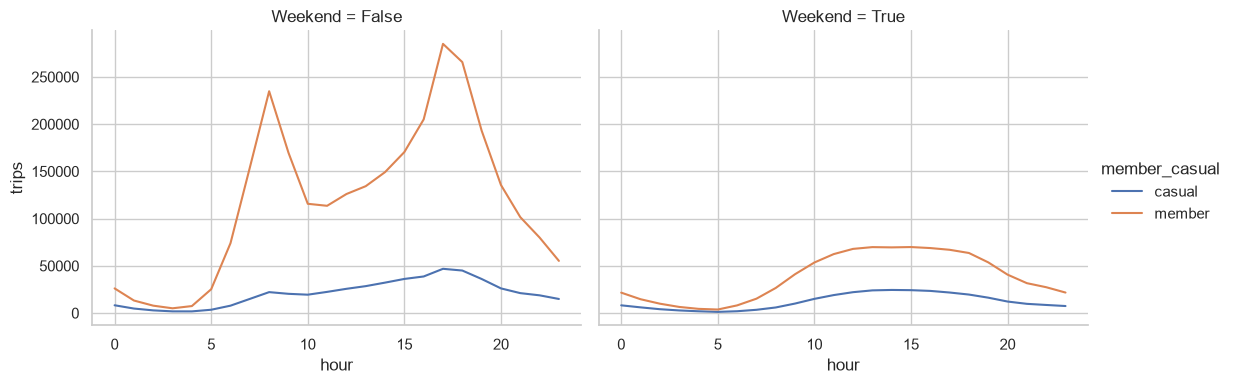

In [15]:
hourly = (df.groupby(["hour","member_casual","is_weekend"], observed=True)
            .size().reset_index(name="trips"))
g = sns.relplot(data=hourly, x="hour", y="trips", hue="member_casual",
                col="is_weekend", kind="line", height=4, aspect=1.4)
g.set_titles("Weekend = {col_name}")
plt.show()

### 5c. Demand per month and weekday

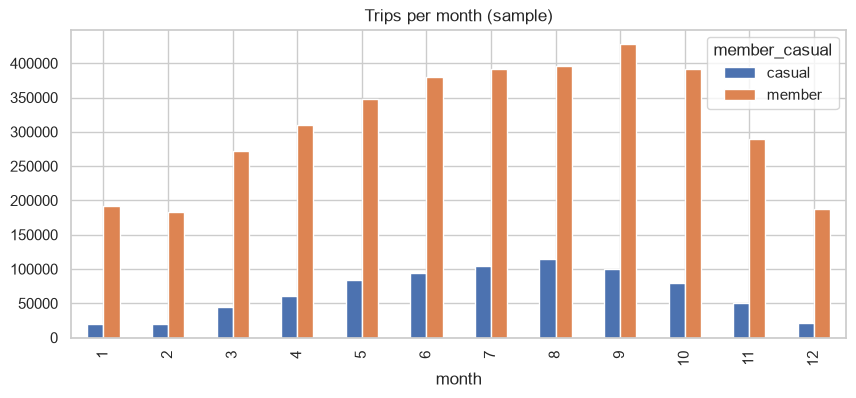

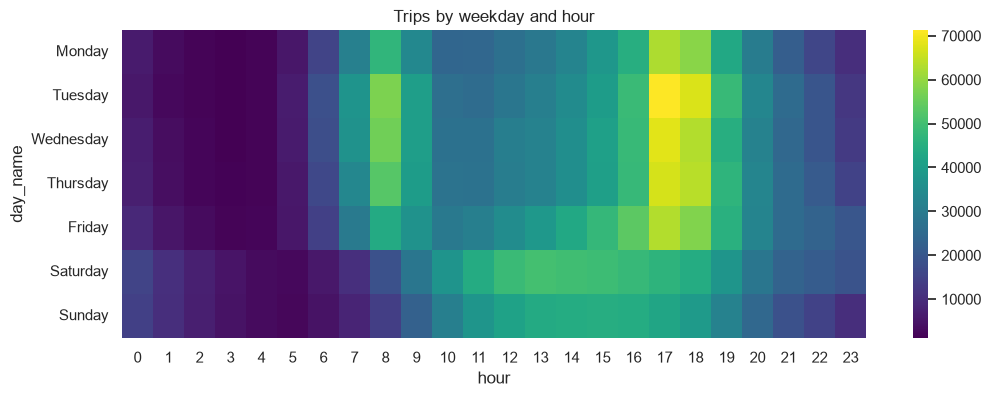

In [16]:
monthly = df.groupby(["month","member_casual"], observed=True).size().unstack()
monthly.plot(kind="bar", figsize=(10,4), title="Trips per month (sample)")
plt.show()

pivot = df.pivot_table(index="day_name", columns="hour", values="ride_id",
                       aggfunc="count", observed=True)
plt.figure(figsize=(12,4))
sns.heatmap(pivot, cmap="viridis")
plt.title("Trips by weekday and hour")
plt.show()

### 5d. Duration by rider type and bike type

count  median  mean   std
member_casual rideable_type                             
casual        classic_bike    197967    15.3  22.2  44.0
              electric_bike   596382    11.9  17.3  21.8
member        classic_bike   1153258     7.6  11.0  20.3
              electric_bike  2614738     8.4  11.0   9.3

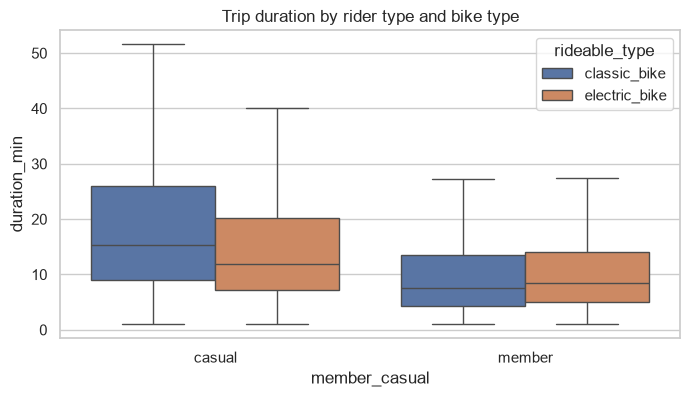

In [17]:
agg = (df.groupby(["member_casual","rideable_type"], observed=True)["duration_min"]
         .agg(["count","median","mean","std"]).round(1))
display(agg)

plt.figure(figsize=(8,4))
sns.boxplot(data=df.sample(min(300_000, len(df)), random_state=1),
            x="member_casual", y="duration_min", hue="rideable_type", showfliers=False)
plt.title("Trip duration by rider type and bike type")
plt.show()

## 6. Testable hypotheses
Before building any model we check that there is a real pattern to predict. All tests use a significance level of 0.05, and because with millions of rows *everything* becomes significant, we also report an **effect size**.

**H1:** Casual riders take longer trips than members.
- H0: duration distributions are equal. Test: Mann-Whitney U (duration is heavily skewed, so no t-test). Effect size: probability of superiority.

**H2:** Members ride mainly in commuting hours, casual riders do not.
- H0: share of trips in rush hours is independent of rider type. Test: chi-square on a contingency table, effect size Cramer's V.

**H3 (relevant for the model):** Hourly demand depends on the hour of the day and the season.
- Test: Kruskal-Wallis on hourly trip counts across seasons, and Spearman correlation between hour and ... (see below).

In [18]:
# ---- H1: Mann-Whitney on duration ----
rng = np.random.default_rng(42)
mem = df.loc[df.member_casual == "member", "duration_min"]
cas = df.loc[df.member_casual == "casual", "duration_min"]
mem_s = mem.sample(min(200_000, len(mem)), random_state=1)
cas_s = cas.sample(min(200_000, len(cas)), random_state=1)

u, p = stats.mannwhitneyu(cas_s, mem_s, alternative="greater")
prob_sup = u / (len(cas_s) * len(mem_s))
print(f"Median duration  casual: {cas.median():.1f} min | member: {mem.median():.1f} min")
print(f"H1: U={u:.3g}, p={p:.3g}, P(casual longer than member)={prob_sup:.3f}  (0.5 = no effect)")

Median duration  casual: 12.6 min | member: 8.2 min
H1: U=2.63e+10, p=0, P(casual longer than member)=0.657  (0.5 = no effect)


In [19]:
# ---- H2: chi-square, rush-hour share by rider type ----
df["is_rush"] = df["part_of_day"].isin(["morning_rush","evening_rush"])
wk = df[~df.is_weekend]
ct = pd.crosstab(wk["member_casual"], wk["is_rush"])
display(ct)
chi2, p, dof, _ = stats.chi2_contingency(ct)
cramers_v = np.sqrt(chi2 / ct.values.sum())     # 2x2 table
print(f"H2: chi2={chi2:.3g}, p={p:.3g}, Cramer's V={cramers_v:.3f}")
print(wk.groupby("member_casual", observed=True)["is_rush"].mean().round(3))

is_rush,False,True
member_casual,,
casual,268410,232116
member,1266657,1581556


H2: chi2=1.44e+04, p=0, Cramer's V=0.066
member_casual
casual    0.464
member    0.555
Name: is_rush, dtype: float64


In [20]:
# ---- H3: hourly demand differs per season ----
hourly_counts = (df.groupby(["date","hour","season"], observed=True)
                   .size().reset_index(name="trips"))
groups = [g["trips"].values for _, g in hourly_counts.groupby("season", observed=True)]
h, p = stats.kruskal(*groups)
eps2 = (h - len(groups) + 1) / (len(hourly_counts) - len(groups))   # epsilon-squared effect size
print(f"H3: H={h:.3g}, p={p:.3g}, epsilon^2={eps2:.3f}")
display(hourly_counts.groupby("season", observed=True)["trips"].median().to_frame("median trips/hour"))

# hour of day has a non-linear (daily cycle) effect, so compare across hours instead of Spearman
h2, p2 = stats.kruskal(*[g["trips"].values for _, g in hourly_counts.groupby("hour")])
print(f"Hour of day: H={h2:.3g}, p={p2:.3g}")

H3: H=985, p=2.6e-213, epsilon^2=0.112


,median trips/hour
season,
winter,253.0
spring,452.0
summer,682.0
autumn,560.0


Hour of day: H=5.9e+03, p=0


**Conclusions (rewrite in your own words after running):**
- H1: ... (accept/reject, effect size small/medium/large?)
- H2: ...
- H3: ...

These patterns tell us what is worth predicting: e.g. **hourly demand per station or per area** (regression), or **rider type** (classification, member vs casual) from duration, time and bike type.

## 7. Save the cleaned data
This is the input for the next notebook. We also keep the cleaning rules in one place for the final `03_prepare.ipynb` (no graphs).

In [21]:
keep = ["ride_id","rideable_type","started_at","ended_at","start_station_name","start_station_id",
        "end_station_name","end_station_id","start_lat","start_lng","end_lat","end_lng",
        "member_casual","duration_min","distance_km","hour","month","is_weekend",
        "day_name","season","part_of_day"]
df[keep].to_parquet("citibike_data/citibike_clean.parquet", index=False)
print("Saved", len(df), "rows")

Saved 4562345 rows
